# Motional Wigner functions at weak dephasing

Compare the unsqueezed $|1\rangle$ and $|2\rangle$ preparations after a real displacement signal $\beta=1$ and before the $\alpha$ readout. Each snapshot is a separate run at the same pulse duration and equal integrated heating and cooling $G_h=G_c=0.01$. The first figure resolves $0\leq G_\phi=\Gamma_\phi t_{\rm sig}\leq1$. The second gives three reference points extending to strong dephasing.

This uses the normalized-time signal and jump operators from [1121](1121_dephasing_reentrance.ipynb) in the QuantumOptics master-equation solver. The Wigner section in that notebook uses $G_h=G_c=0.003$. Here the bath matches the earlier $n=1$ to $n=2$ sensing crossover near 29.60. A white cross marks the origin, an open circle marks the density-matrix centroid, and a black contour traces zero. The colors saturate at ±0.2 in every panel.

In [ ]:
import Pkg
Pkg.activate(@__DIR__)
using PyPlot

In [ ]:
using LinearAlgebra
import QuantumOptics as QO

weak_G = [0., 0.01, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.75, 0.90, 1.]
context_G = [4., 29.60, 100.]
focks = [1, 2]
beta = 1.0
bath = 0.01
b = QO.FockBasis(29)  # 30 motional levels, starting at |0>
a = QO.destroy(b)
num = QO.number(b)
H = im * beta * (QO.dagger(a) - a)
X = (a + QO.dagger(a)) / sqrt(2)
quad = collect(-4.:0.1:4.)
function snapshot(n, g)
    jumps = [sqrt(bath)*a, sqrt(bath)*QO.dagger(a), sqrt(g)*num]
    initial = QO.dm(QO.fockstate(b, n))
    _, states = QO.timeevolution.master([0.,1.], initial, H, jumps;
                                        reltol=1e-9, abstol=1e-12)
    rho = last(states)
    center = real(QO.expect(X, rho))
    expected = sqrt(2)*beta*(iszero(g) ? 1.0 : -2*expm1(-g/2)/g)
    @assert abs(center-expected) < 1e-7
    @assert abs(tr(rho)-1) < 1e-8 && abs(sum(diag(rho.data)[end-4:end])) < 1e-8
    return (W=QO.wigner(rho, quad, quad), center=center)
end
snapshots = Dict((n,g) => snapshot(n,g) for n in focks for g in vcat(weak_G,context_G));

In [ ]:
function wigner_sheet(values, cols)
    blocks = cld(length(values), cols)
    fig, axes = subplots(2blocks, cols, squeeze=false, sharex=true, sharey=true,
                         figsize=(2cols+1.1, 2.05*(2blocks)+1), constrained_layout=true)
    image = nothing
    for (i,n) in enumerate(focks), (j,g) in enumerate(values)
        row = (i-1)*blocks + cld(j,cols)
        col = mod1(j,cols)
        ax = axes[row,col]
        s = snapshots[n,g]
        image = ax.pcolormesh(quad,quad,permutedims(s.W),cmap="RdBu_r",
                              vmin=-0.2,vmax=0.2,shading="nearest")
        ax.contour(quad,quad,permutedims(s.W),levels=[0.],colors="#555555",linewidths=0.6)
        ax.plot(0,0,"w+",ms=7)
        ax.plot(s.center,0,"o",mfc="none",mec="black",ms=6)
        ax.set(aspect="equal",title="Γφt = $g",xticks=[-3,0,3],yticks=[-3,0,3])
        col == 1 && ax.set_ylabel("|$n⟩   p")
        row == 2blocks && ax.set_xlabel("x")
    end
    fig.colorbar(image,ax=vec(axes),label="W(x,p)",extend="both",shrink=0.75)
    fig.suptitle("Motional Wigner function before readout\nβ = 1,  Gₕ = Gc = 0.01     + origin    ○ centroid")
    return fig
end

## Weak dephasing

Read each pair of rows left to right for one preparation. The zero-dephasing column includes the complete drive and balanced bath.

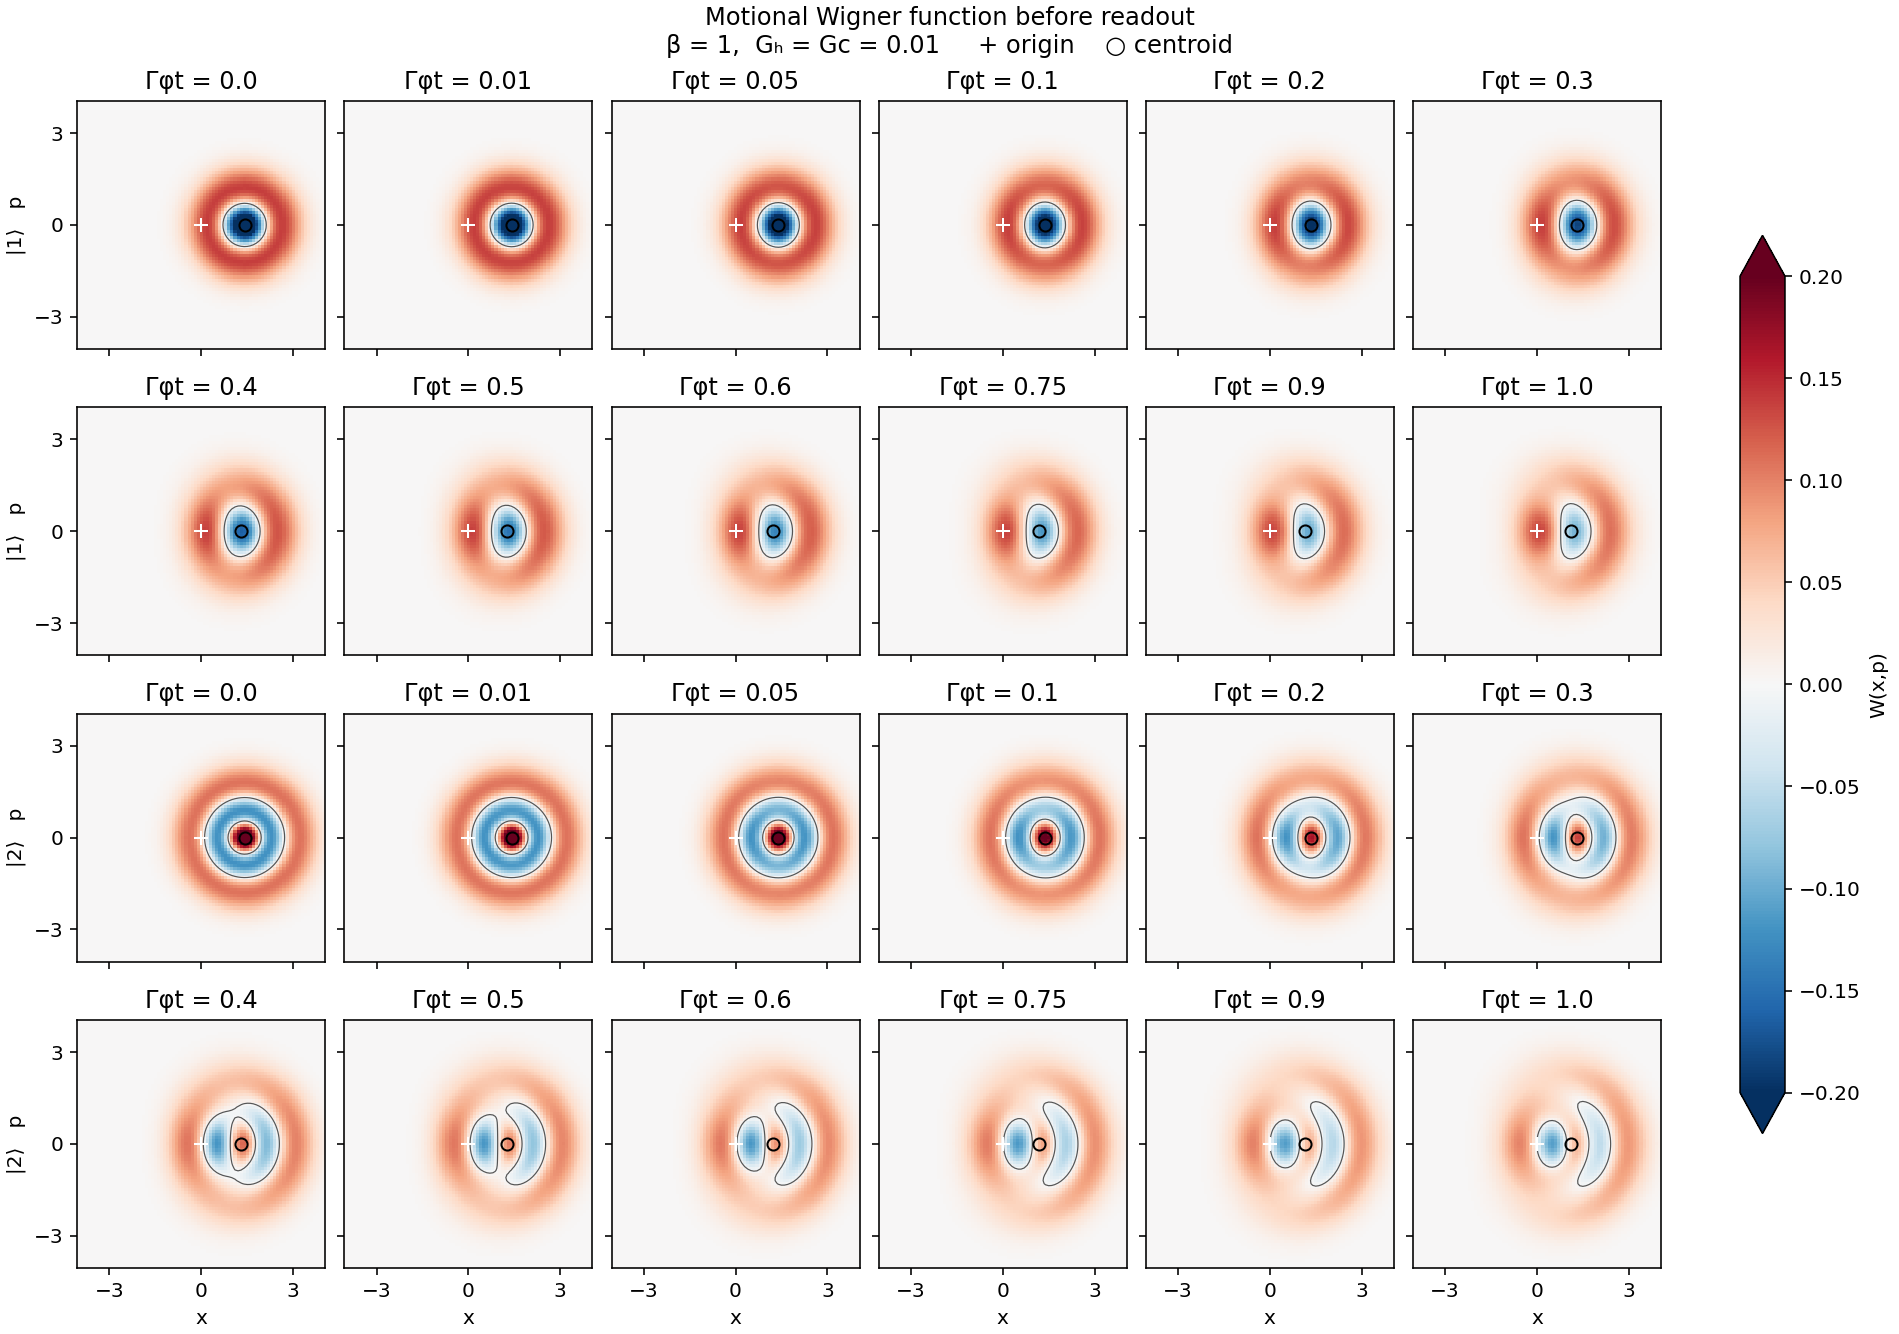

In [ ]:
fig = wigner_sheet(weak_G, 6)
display(fig)
close(fig);

## Larger dephasing

The middle reference is the previously calculated sensing crossover for this bath. The snapshots here compare motional states at that point.

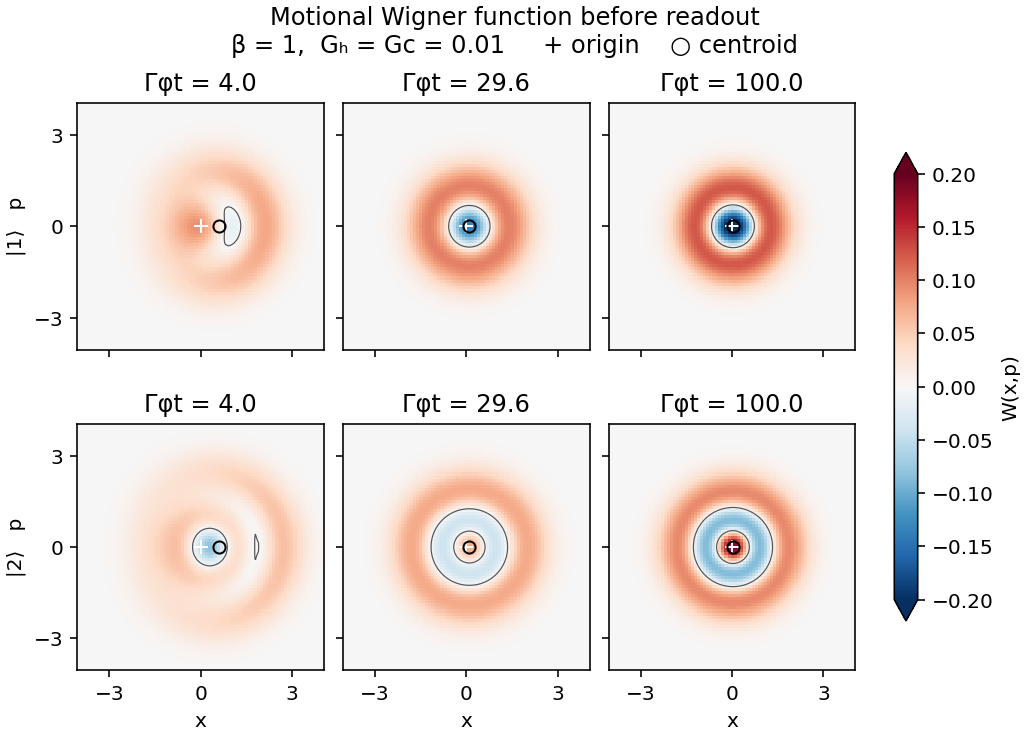

In [ ]:
fig = wigner_sheet(context_G, 3)
display(fig)
close(fig);

## Reading the weak sweep

The centroid moves from x = 1.414 at zero dephasing to 1.251 at $G_\phi=0.5$ and 1.113 at $G_\phi=1$. Both preparations have the same centroid trajectory. The negative disk and annulus respond differently to the noise. The simulation checks the centroid against the balanced-bath first-moment solution at every point.